# Packages and functions

In [1]:
import os
import time
import umap
import random
import numpy as np
import pandas as pd
import colorsys as cs
import seaborn as sns
from scipy.stats import norm
import matplotlib.pyplot as plt
from scipy.spatial import procrustes, distance_matrix
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.spatial.distance import cdist
import scipy
#import tools as tl
import scanpy as sc
from sklearn.metrics.pairwise import cosine_similarity
import anndata as ad

def get_pa(pos_recon, pos_truth):
    pos_recon = pd.DataFrame(pos_recon, columns = [['xcoord','ycoord']])
    mtx1, mtx2, disparity = procrustes(pos_truth[['xcoord','ycoord']], pos_recon[['xcoord','ycoord']])
    
    pos_truth_translate = pos_truth.copy()
    pos_truth_translate['xcoord'] = pos_truth_translate['xcoord'] - np.mean(pos_truth_translate['xcoord'])
    pos_truth_translate['ycoord'] = pos_truth_translate['ycoord'] - np.mean(pos_truth_translate['ycoord'])
    
    scaling = np.sqrt(np.trace(np.dot(pos_truth_translate[['xcoord','ycoord']], pos_truth_translate[['xcoord','ycoord']].T)))
    scaling_2 = np.sqrt(np.trace(np.dot(pos_truth_translate[['xcoord','ycoord']], pos_truth_translate[['xcoord','ycoord']].T)))/np.sqrt(np.trace(np.dot(mtx2, mtx2.T)))

    mtx1_scaled = mtx1*scaling
    mtx2_scaled = mtx2*scaling_2
    
    return mtx2_scaled

/Users/ConradOakes/miniconda3/envs/op_error_test/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Load Real Data

In [2]:
np.random.seed(42)

In [3]:
import scipy.sparse as sp 
from collections import Counter
import editdistance

# generate spase matrix from matching, with selection on anchor and target
def get_matrix(match_df,min_a_cnt,max_a_cnt, min_t_cnt,max_t_cnt, anchor, target):
    a_all = match_df.groupby(anchor)['cnt'].sum().reset_index(name='total_cnt')  
    a_sel = a_all.loc[(a_all['total_cnt']>min_a_cnt) & (a_all['total_cnt']<max_a_cnt),]
    t_all = match_df.groupby(target)['cnt'].sum().reset_index(name='total_cnt')  
    t_sel = t_all.loc[(t_all['total_cnt']>min_t_cnt) & (t_all['total_cnt']<max_t_cnt),]
    match_df = match_df[(match_df[anchor].isin(a_sel[anchor])) & (match_df[target].isin(t_sel[target]))]
    a_list = match_df.groupby(anchor)['cnt'].sum().reset_index(name='total_cnt') 
    t_list = match_df.groupby(target)['cnt'].sum().reset_index(name='total_cnt') 
    print('a: {}'.format(len(a_list)))
    print('t: {}'.format(len(t_list)))
    a_dict = dict()
    t_dict = dict()
    for i in range(len(a_list)):
        a_dict[a_list.iloc[i,0]] = i
    for j in range(len(t_list)):
        t_dict[t_list.iloc[j,0]] = j
    a_coo = []
    t_coo = []
    [a_coo.append(a_dict[a]) for a in match_df[anchor]]
    [t_coo.append(t_dict[t]) for t in match_df[target]]
    counts_coo = sp.coo_matrix((match_df['cnt'], (a_coo, t_coo)))
    # counts = counts_coo.tocsr().toarray()
    counts = counts_coo.tocsr()
    return counts, a_list, t_list

def build_6mer_dist(bc_list):
    start_km = {}
    mid_km = {}
    end_km = {}
    for bc in bc_list:
        start_km.setdefault(bc[:6] , []).append(bc)
        mid_km.setdefault(bc[4:10], []).append(bc)
        end_km.setdefault(bc[-6:] , []).append(bc)
    return start_km,mid_km,end_km

def barcode_matching(bc_pos_dict,spatial_bc_list,max_dist=1):
    bc_matching_dict = {}
    def get_sel_bc(bc):
        res = []
        if bc[:6] in start_km:
            res += start_km[bc[:6]]
        if bc[-6:] in end_km:
            res += end_km[bc[-6:]]
        if bc[4:10] in mid_km:
            res += mid_km[bc[4:10]]
        return set(res)
    exact_match = 0
    fuzzy_match = 0
    bc_ref_list = list(bc_pos_dict.keys())
    start_km,mid_km,end_km = build_6mer_dist(bc_ref_list)
    for bc in spatial_bc_list:
        bc_old = bc
        #bc = "".join([bc[it] for it in [1,2,3,4,5,6,7,9,10,11,12,13] ])
        if bc in bc_pos_dict:
            exact_match += 1
            bc_matching_dict[bc_old] = bc
        else:
            sel_bc = get_sel_bc(bc)
            #sel_bc = bc_ref_list
            if len(sel_bc)>0:
                fz = [(it, editdistance.eval(it, bc)) for it in sel_bc]
                fz = [it for it in fz if it[1]<=max_dist]
                fz.sort(key=lambda x:x[1])
                if len(fz)==0:
                    continue
                ## if there are two barcodes with the same edit distance, choose the one with higher error rate in the last base
                if len(fz)>1 and fz[0][1]==fz[1][1]:
                    if editdistance.eval(fz[0][0][:-1], bc[-1])>editdistance.eval(fz[1][0][:-1], bc[-1]):  # higher error rate in the last base of the barcode
                        fuzzy_match += 1
                        bc_matching_dict[bc_old] = fz[1][0]
                    elif editdistance.eval(fz[0][0][:-1], bc[-1])<editdistance.eval(fz[1][0][:-1], bc[-1]):
                        fuzzy_match += 1
                        bc_matching_dict[bc_old] = fz[0][0]
                else:
                    fuzzy_match += 1
                    bc_matching_dict[bc_old] = fz[0][0]
    return bc_matching_dict,exact_match,fuzzy_match

In [4]:
anchor = 'V10' #anchor beads as the bead type what we want coordinates, the polyT beads in Slide-seq and polyA beads in Slide-tags
target = 'V9A30' #target beads as the bead type whose coordinates won't be used in spatial transcriptomics

# load barcode-barcode conjugation information
blind_raw = pd.read_csv('../data/c58_8_blind_raw_reads_filtered.csv.gz', compression='gzip')
blind_sum = blind_raw.groupby(['R1_bc', 'R2_bc']).sum().reset_index()[['R1_bc', 'R2_bc', 'reads']]
blind_sum.columns = [anchor,target,'cnt']

# statistics of umi per bead
a_all = blind_sum.groupby(anchor)['cnt'].sum().reset_index(name='total_cnt')
t_all = blind_sum.groupby(target)['cnt'].sum().reset_index(name='total_cnt')

# statistics of covered bead per bead
a_cover_bc = blind_sum.groupby(anchor).count()
t_cover_bc = blind_sum.groupby(target).count()

blind_sum.head()

,V10,V9A30,cnt
0,AAAAAAAGTCTGGT,AAAGCTCTGCGAGA,1
1,AAAAAAAGTCTGGT,AAAGGATCTTCTGC,1
2,AAAAAAAGTCTGGT,AAATGTCTGATGGG,1
3,AAAAAAAGTCTGGT,AACAAGGTACACAG,1
4,AAAAAAAGTCTGGT,AACGAGGAGGTCGC,3


In [5]:
# load beads ground truth location from in situ sequencing, center to (0,0), and scale from pixel to um
pos = pd.read_csv('../data/c58_8_matched_bead_location.csv.gz', compression='gzip')
pos['xcoord'] = pos['xcoord']-np.mean(pos['xcoord']) # ~2563
pos['ycoord'] = pos['ycoord']-np.mean(pos['ycoord']) # ~2580
pos['xcoord'] = pos['xcoord']*0.72
pos['ycoord'] = pos['ycoord']*0.72
RADIUS=np.mean((pos[['xcoord', 'ycoord']].max() - pos[['xcoord', 'ycoord']].min())/2)
print(RADIUS)

1536.9462


In [6]:
time0 = time.time()
# define filtering of beads based on minmum or maximum count per bead
a_min = 0
a_max = 100000
t_min = 0
t_max = 100000

# construct anchor by target diffusion matrix
counts_temp, a_temp, t_temp = get_matrix(blind_sum, min_a_cnt=a_min, max_a_cnt=a_max, min_t_cnt=t_min, max_t_cnt=t_max, anchor=anchor, target=target)

a: 19408
t: 19681


In [7]:
# Barcode filtering
a_match_dict,_,_= barcode_matching(Counter(pos['barcode']), a_temp[anchor].values, max_dist = 1)
t_match_dict,_,_= barcode_matching(Counter(pos['barcode']), t_temp[target].values, max_dist = 1)


a_match_df = pd.DataFrame({'barcode':a_match_dict.keys(),
              'matched':a_match_dict.values()})
t_match_df = pd.DataFrame({'barcode':t_match_dict.keys(),
              'matched':t_match_dict.values()})
a_sel = a_temp[a_temp[anchor].isin(a_match_df.matched.unique())]
t_sel = t_temp[t_temp[target].isin(t_match_df.matched.unique())]
counts = pd.DataFrame(counts_temp.toarray()).loc[a_temp[anchor].isin(a_match_df.matched.unique()), t_temp[target].isin(t_match_df.matched.unique())].values

print(a_sel.shape, t_sel.shape)
a_sel = pd.merge(a_sel, pos, how = 'left', left_on = anchor, right_on='barcode')
t_sel = pd.merge(t_sel, pos, how = 'left', left_on = target, right_on='barcode')
print(a_sel.shape, t_sel.shape)

(12033, 2) (12789, 2)
(12033, 5) (12789, 5)


In [8]:
adata = ad.AnnData(counts, obs = a_sel, var = t_sel)
# filter to those with ground truth info
adata = adata[~adata.obs.xcoord.isna(),~adata.var.xcoord.isna()]
# filter to those with relevant number of counts
adata = adata[np.max(adata.X, axis=1) > 10, np.max(adata.X, axis=0) > 10]
adata.obs = adata.obs.reset_index(drop=True).set_index('barcode')[['xcoord', 'ycoord']]
adata.var = adata.var.reset_index(drop=True).set_index('barcode')[['xcoord', 'ycoord']]
adata

/Users/ConradOakes/miniconda3/envs/op_error_test/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/Users/ConradOakes/miniconda3/envs/op_error_test/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


AnnData object with n_obs × n_vars = 12030 × 12786
    obs: 'xcoord', 'ycoord'
    var: 'xcoord', 'ycoord'

In [9]:
counts = adata.X
adata.obs = adata.obs.reset_index().set_index('barcode')[['xcoord', 'ycoord']]
adata.var = adata.var.reset_index().set_index('barcode')[['xcoord', 'ycoord']]
adata

AnnData object with n_obs × n_vars = 12030 × 12786
    obs: 'xcoord', 'ycoord'
    var: 'xcoord', 'ycoord'

In [10]:
import scanpy as sc
from sklearn.metrics.pairwise import cosine_similarity

cos_counts = cosine_similarity(adata.X)
#log_cos_counts = cosine_similarity(np.log1p(adata.X))


In [11]:
np.random.seed(42)

time_start = time.time()
reducer = umap.UMAP(metric='cosine',
                    n_neighbors=25, 
                    min_dist=0.99, 
                    low_memory=False, 
                    n_components=2, 
                    verbose=True,           
                    n_epochs=10000,                    
                    learning_rate = 1)
embedding = reducer.fit_transform(adata.X)
time_loop = time.time()
print('umap time: ', time_loop-time_start)

UMAP(angular_rp_forest=True, learning_rate=1, low_memory=False, metric='cosine', min_dist=0.99, n_epochs=10000, n_neighbors=25, verbose=True)


Wed Sep 23 21:37:58 2026 Construct fuzzy simplicial set


Wed Sep 23 21:37:59 2026 Finding Nearest Neighbors
Wed Sep 23 21:37:59 2026 Building RP forest with 10 trees


Wed Sep 23 21:38:04 2026 NN descent for 14 iterations


	 1  /  14


...

Epochs completed: 100%| █████████▉ 9979/10000 [00:55]

Epochs completed: 100%| █████████▉ 9999/10000 [00:55]

Epochs completed: 100%| ██████████ 10000/10000 [00:55]

Wed Sep 23 21:39:17 2026 Finished embedding


umap time:  81.15829014778137


## calculate error distribution

In [12]:
embedding_df = get_pa(embedding, adata.obs[['xcoord', 'ycoord']])
embedding_df

array([[  542.53311574,   850.64057132],
       [  275.81548694,   -56.98514378],
       [-1048.66816703,  -731.46916542],
       ...,
       [ -575.48587965,   186.35311237],
       [ -794.42701477,  -579.57916732],
       [  558.09132793,   340.95256221]])

In [13]:
adata.obs.head()

,xcoord,ycoord
barcode,,
AAAAACACAAGATG,596.168785,828.367029
AAAAACCAAGGGCG,324.080785,-83.440971
AAAAACCACTAGCC,-1089.927215,-735.616971
AAAAACCCTTTGCA,986.408785,-994.168971
AAAAACGTTATATC,-316.215215,172.735029


In [14]:
embedding_df[:,0]

array([  542.53311574,   275.81548694, -1048.66816703, ...,
        -575.48587965,  -794.42701477,   558.09132793])

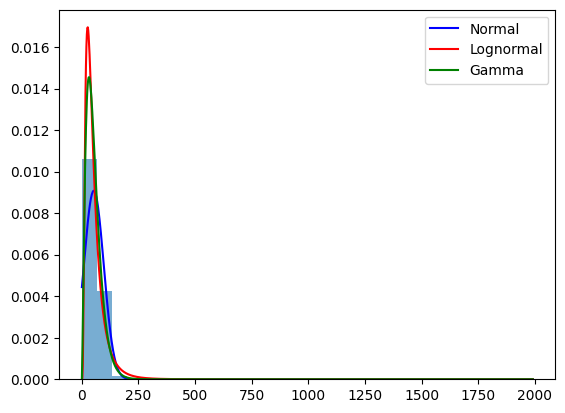

In [15]:
import scipy.stats as stats

data = np.linalg.norm(embedding_df - adata.obs.values, axis=1)
mu, std = stats.norm.fit(data)
loglik = np.sum(stats.norm.logpdf(data, mu, std))
k = 2  # number of parameters
aic = 2*k - 2*loglik
x = np.linspace(min(data), max(data), 1000)
pdf = stats.norm.pdf(x, mu, std)

# Fit lognormal
shape, loc, scale = stats.lognorm.fit(data, floc=0)

# Plot
x = np.linspace(min(data), max(data), 1000)
pdf_ln = stats.lognorm.pdf(x, shape, loc, scale)

shape_g, loc_g, scale_g = stats.gamma.fit(data, floc=0)
pdf_g = stats.gamma.pdf(x, shape_g, loc_g, scale_g)

plt.hist(data, bins=30, density=True, alpha=0.6)
plt.plot(x, pdf, 'b', label='Normal')
plt.plot(x, pdf_ln, 'r', label='Lognormal')
plt.plot(x, pdf_g, 'g', label='Gamma')
plt.legend()
plt.show()


/var/folders/kj/wm2vrp3x04qgzq18l2rkrcxh0000gn/T/ipykernel_23293/2887021314.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


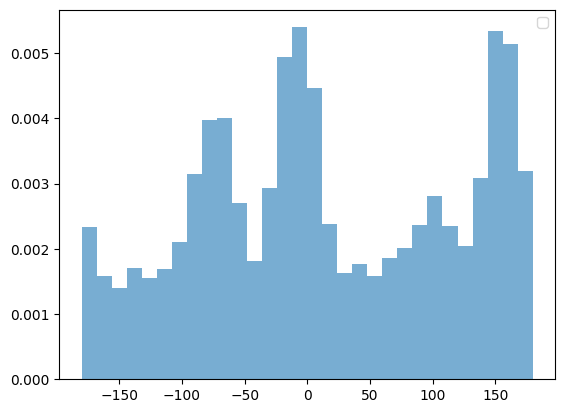

In [16]:
dx = embedding_df[:,0] - adata.obs['xcoord']
dy = embedding_df[:,1] - adata.obs['ycoord']

# Angle in radians
angle_rad = np.arctan2(dy, dx)

# Convert to degrees (optional)
angle_deg = np.degrees(angle_rad)

plt.hist(angle_deg, bins=30, density=True, alpha=0.6)
plt.legend()
plt.show()

In [17]:
from scipy.stats import kstest

ks_statistic, p_value = stats.kstest(angle_deg, 'uniform', args=(-180, 360))

print("KS Statistic:", ks_statistic)
print("P-value:", p_value)


KS Statistic: 0.08592695669265549
P-value: 9.998353998763826e-78


Text(0, 0.5, 'error_magnitude')

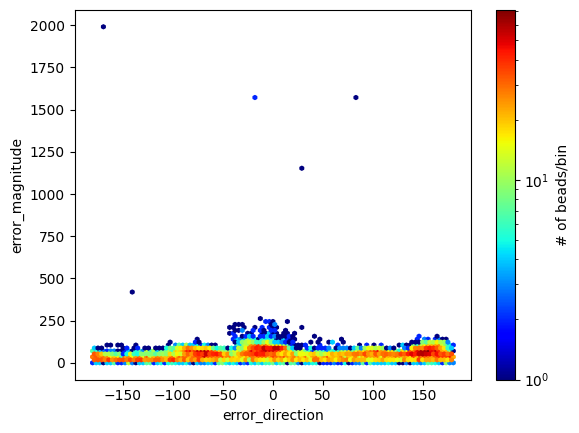

In [18]:
plt.hexbin(angle_deg, data, gridsize=100, cmap='jet', bins='log')
plt.colorbar(label='# of beads/bin')
plt.xlabel('error_direction')
plt.ylabel('error_magnitude')

In [19]:
loglik_lognorm = np.sum(stats.lognorm.logpdf(data, shape, loc, scale))
loglik_gamma = np.sum(stats.gamma.logpdf(data, shape_g, loc_g, scale_g))

aic_lognorm = 2*3 - 2*loglik_lognorm
aic_gamma = 2*3 - 2*loglik_gamma

print("AIC lognormal:", aic_lognorm)
print("AIC gamma:", aic_gamma)
print("AIC norm:", aic)


AIC lognormal: 116241.42974752121
AIC gamma: 115121.31302884348
AIC norm: 125159.0293813516


# Load Spatial dataset

In [20]:
np.random.seed(42)

fn = "../data/cerebellum_processed.h5ad"

ad = sc.read_h5ad(fn)
ad.obs['x'] = ad.obsm['spatial'][:, 0]
ad.obs['y'] = ad.obsm['spatial'][:, 1]
# convert pixels to um (Slide-seq)
ad.obs['x'] = ad.obs['x']-np.mean(ad.obs['x']) # ~2563
ad.obs['y'] = ad.obs['y']-np.mean(ad.obs['y']) # ~2580
ad.obs['x'] = ad.obs['x']*0.72
ad.obs['y'] = ad.obs['y']*0.72
ad.obsm['spatial'] = ad.obs[['x', 'y']].values
ad

AnnData object with n_obs × n_vars = 9985 × 10121
    obs: 'row', 'col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_counts', 'n_genes', 'x', 'y'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca', 'spatial'
    varm: 'PCs'

## Add error

In [21]:
# generate error -- local, explicitly-seeded RNG (not the global
# np.random.seed(42) set many cells earlier, which has since been
# consumed by UMAP/Gaston/GLM-PCA and no longer determines this draw)
err_rng = np.random.RandomState(42)
ad.obs['error'] = stats.gamma.rvs(shape_g, loc=loc_g, scale=scale_g, size=len(ad.obs), random_state=err_rng)
# generate random direction 
theta = err_rng.uniform(0, 2*np.pi, size=len(ad.obs))
ad.obs['x_err'] = ad.obs['x'] + ad.obs['error'] * np.cos(theta)
ad.obs['y_err'] = ad.obs['y'] + ad.obs['error'] * np.sin(theta)
ad.obsm['spatial_err'] = ad.obs[['x_err', 'y_err']].values
ad

AnnData object with n_obs × n_vars = 9985 × 10121
    obs: 'row', 'col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_counts', 'n_genes', 'x', 'y', 'error', 'x_err', 'y_err'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca', 'spatial', 'spatial_err'
    varm: 'PCs'

## Alternative error models: identity-swap mixture, and direct graph corruption

The model above draws every bead's displacement i.i.d. from a single continuous
Gamma distribution -- smooth, isotropic jitter, roughly equal treatment for every
bead. That is not what the split-half resampling analysis (on the real Hu c58_8
reconstruction, elsewhere in this project) actually found: ~18-24% of a bead's
neighbours change IDENTITY from pure sampling noise, i.e. a *minority* of edges
are simply wrong (point to an unrelated bead), not every bead nudged a bit. Two
alternative models below are calibrated directly to that measurement instead of a
curve fit to an aggregate displacement histogram, and are run *alongside* (not
instead of) the smooth-Gamma model so conclusions can be checked for robustness to
the choice of noise model, not just its magnitude.

In [22]:
from scipy.spatial import KDTree


def inject_mixture_error(true_xy, p_swap=0.20, local_bias=False, local_k=50, rng=None):
    """Two-component position corruption, calibrated to the split-half
    neighbour-turnover rate (~0.18-0.24 Jaccard distance at k=5-25):
      - (1-p_swap) of beads: keep their true position
      - p_swap of beads: JUMP to the true position of a different, randomly
        chosen bead -- mimicking a genuine identity/neighbour misassignment
        (the mechanism split-half resampling demonstrated), not gentle jitter
        around the truth. Mirrors the uniform-redistribution crosstalk model
        used elsewhere in this project (decontaminate.py's crosstalk()).
    local_bias=True restricts the swap target to one of the bead's own
    local_k true nearest neighbours (a 'confusable near-miss') instead of a
    totally unrelated bead anywhere on the array -- optional refinement.
    """
    rng = rng or np.random.RandomState(46)
    n = true_xy.shape[0]
    swapped = rng.random(n) < p_swap
    new_xy = true_xy.copy()
    idx_swapped = np.where(swapped)[0]
    if len(idx_swapped) == 0:
        return new_xy, swapped
    if local_bias:
        tree = KDTree(true_xy)
        _, nn_idx = tree.query(true_xy[idx_swapped], k=local_k + 1)
        choice = rng.randint(1, local_k + 1, size=len(idx_swapped))  # exclude self (col 0)
        targets = nn_idx[np.arange(len(idx_swapped)), choice]
    else:
        targets = rng.randint(0, n, size=len(idx_swapped))
        # avoid a bead 'swapping' to itself
        same = targets == idx_swapped
        while same.any():
            targets[same] = rng.randint(0, n, size=same.sum())
            same = targets == idx_swapped
    new_xy[idx_swapped] = true_xy[targets]
    return new_xy, swapped


def corrupt_knn_graph(true_xy, n_neighbors=30, p_swap=0.20, rng=None):
    """Directly corrupt a fraction of each bead's k-NN edges by swapping them
    for uniformly random unrelated beads -- the graph-level analog of
    inject_mixture_error, and the most direct implementation of what
    split-half resampling actually measured (neighbour IDENTITY swaps),
    with no positional-perturbation layer in between. Matches the format
    concordex.tools.calculate_concordex expects at adata.obsm['adjacency']
    (sklearn.neighbors.kneighbors_graph output, include_self=False).
    """
    from sklearn.neighbors import kneighbors_graph
    rng = rng or np.random.RandomState(47)
    n = true_xy.shape[0]
    Adj = kneighbors_graph(true_xy, n_neighbors=n_neighbors, include_self=False).tolil()
    for i in range(n):
        neighbors_i = list(Adj.rows[i])
        n_swap = rng.binomial(len(neighbors_i), p_swap)
        if n_swap == 0:
            continue
        swap_pos = rng.choice(len(neighbors_i), size=n_swap, replace=False)
        for pos in swap_pos:
            old_neighbor = neighbors_i[pos]
            Adj[i, old_neighbor] = 0
            while True:
                new_neighbor = rng.randint(0, n)
                if new_neighbor != i and new_neighbor not in neighbors_i:
                    break
            Adj[i, new_neighbor] = 1
    return Adj.tocsr()

In [23]:
# apply the mixture model for the GASTON comparison, p_swap matched to the
# split-half k=5-10 Jaccard range (~0.20-0.24)
mix_rng_gaston = np.random.RandomState(48)
spatial_mix, mix_swapped_gaston = inject_mixture_error(ad.obsm['spatial'], p_swap=0.20, rng=mix_rng_gaston)
ad.obsm['spatial_mix'] = spatial_mix
print(f"GASTON mixture model: {mix_swapped_gaston.sum()} / {len(mix_swapped_gaston)} "
      f"beads ({mix_swapped_gaston.mean():.1%}) swapped to an unrelated true position")
assert np.allclose(ad.obsm['spatial'], ad.obs[['x', 'y']].values), \
    "clean coordinates were modified while building the mixture model"

GASTON mixture model: 1975 / 9985 beads (19.8%) swapped to an unrelated true position


# Basic Error Metrics

In [22]:
from sklearn.neighbors import KDTree
from numba import njit

@njit
def unique_sorted(a):
    """Return unique sorted values of array a (Numba-compatible)."""
    a = np.sort(a)
    out = [a[0]]
    for i in range(1, a.size):
        if a[i] != a[i-1]:
            out.append(a[i])
    return np.array(out)

@njit
def count_intersection(a, b):
    """Count unique intersection between two sorted unique arrays."""
    i = j = count = 0
    na, nb = a.size, b.size
    while i < na and j < nb:
        if a[i] == b[j]:
            count += 1
            i += 1
            j += 1
        elif a[i] < b[j]:
            i += 1
        else:
            j += 1
    return count

@njit
def count_union_size(a, b):
    """Count unique union size of two sorted unique arrays."""
    i = j = count = 0
    na, nb = a.size, b.size
    while i < na and j < nb:
        if a[i] == b[j]:
            count += 1
            i += 1
            j += 1
        elif a[i] < b[j]:
            count += 1
            i += 1
        else:
            count += 1
            j += 1
    # Add remaining items
    count += (na - i) + (nb - j)
    return count

@njit
def jaccard_distance_numeric_numba(X, Y):
    n = X.shape[0]
    out = np.empty(n, dtype=np.float64)

    for idx in range(n):
        x = unique_sorted(X[idx])
        y = unique_sorted(Y[idx])

        inter = count_intersection(x, y)
        union = count_union_size(x, y)

        out[idx] = 1.0 - (inter / union if union != 0 else 0.0)

    return out


In [23]:
nn_list = np.arange(2, 100, 1).tolist() 


bar_n = ad.obs.shape[0]
jac_list = []
nn_df_list = []

truth_tree = KDTree(ad.obsm['spatial'])

error_tree = KDTree(ad.obsm['spatial_err'])
for nn in nn_list:
    distances, truth_nn = truth_tree.query(ad.obsm['spatial'], k=nn)

    distances, test_nn = error_tree.query(ad.obsm['spatial_err'], k=nn)
    # ignore self
    jac_list += jaccard_distance_numeric_numba(truth_nn[:, 1:nn], test_nn[:, 1:nn]).tolist()
    nn_df_list += bar_n*[nn-1]

In [24]:
median_nn = pd.DataFrame({'nn':nn_df_list,
                         'jac':jac_list})
median_nn.head()

,nn,jac
0,1,1.0
1,1,1.0
2,1,1.0
3,1,1.0
4,1,1.0


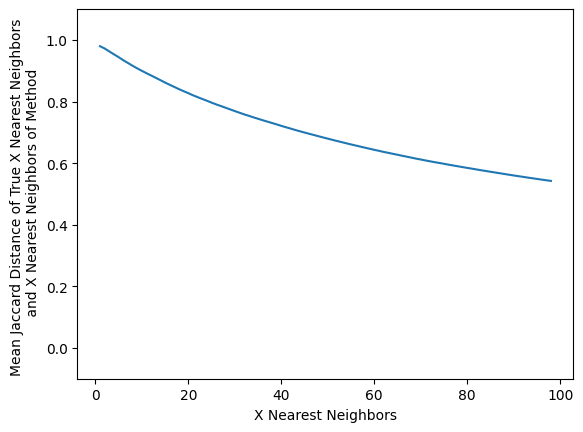

In [25]:
ax = sns.lineplot(median_nn.groupby(['nn']).mean().reset_index(), x = 'nn', y = 'jac'
         )
ax.set_xlabel('X Nearest Neighbors')
ax.set_ylabel('Mean Jaccard Distance of True X Nearest Neighbors \n and X Nearest Neighbors of Method')

plt.ylim(-0.1, 1.1)
plt.show()

In [26]:
true_dist = distance_matrix(ad.obsm['spatial'], ad.obsm['spatial'])
err_dist = distance_matrix(ad.obsm['spatial_err'], ad.obsm['spatial_err'])

calc_error = np.square(true_dist - err_dist)

full_df = pd.DataFrame({
    'true' : true_dist.flatten(),
    'adjusted' : err_dist.flatten(),
    'squared_error' : calc_error.flatten()
})

Text(0, 0.5, 'log(Squared Error+1)')

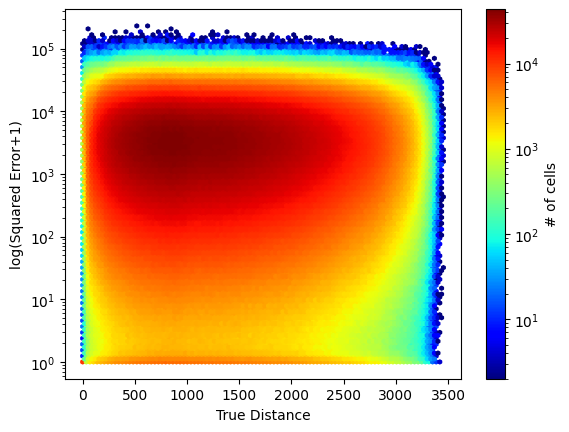

In [27]:
x = full_df['true'].values
y = full_df['squared_error'].values

plt.hexbin(x, y+1, gridsize=100, cmap='jet', bins='log',
          yscale = 'log')
plt.colorbar(label='# of cells')
plt.xlabel("True Distance")
plt.ylabel("log(Squared Error+1)")


# Set up Gaston

In [28]:
import gaston
from gaston import neural_net, cluster_plotting, dp_related, model_selection
from gaston import isodepth_scaling, plot_cell_types, process_NN_output

from glmpca import glmpca

In [29]:
import torch
from gaston.neural_net import GASTON

_original_load = torch.load

def patched_load(*args, **kwargs):
    kwargs["weights_only"] = False
    return _original_load(*args, **kwargs)

torch.load = patched_load

## Using Default Coords

In [30]:
# GLM-PCA parameters
num_dims=8 # 2 * number of clusters
penalty=10 # may need to increase if this is too small

# CHANGE THESE PARAMETERS TO REDUCE RUNTIME
num_iters=30
eps=1e-4
num_genes=30000


counts_mat = ad.X.copy()
coords_mat = ad.obsm['spatial']

counts_mat_glmpca=counts_mat[:,np.argsort(np.sum(counts_mat, axis=0))[-num_genes:]]
glmpca_res=glmpca.glmpca(counts_mat_glmpca.T, num_dims, fam="poi", penalty=penalty, verbose=True,
                        ctl = {"maxIter":num_iters, "eps":eps, "optimizeTheta":True})
A = glmpca_res['factors'] # should be of size N x num_dims, where each column is a PC

Iteration: 0 | deviance=6.0256E+7
Iteration: 1 | deviance=6.0256E+7
Iteration: 2 | deviance=6.0085E+7
Iteration: 3 | deviance=5.7946E+7
Iteration: 4 | deviance=5.7288E+7
Iteration: 5 | deviance=5.7065E+7
Iteration: 6 | deviance=5.6964E+7
Iteration: 7 | deviance=5.6918E+7
Iteration: 8 | deviance=5.6892E+7
Iteration: 9 | deviance=5.6875E+7
Iteration: 10 | deviance=5.6864E+7
Iteration: 11 | deviance=5.6856E+7
Iteration: 12 | deviance=5.6849E+7


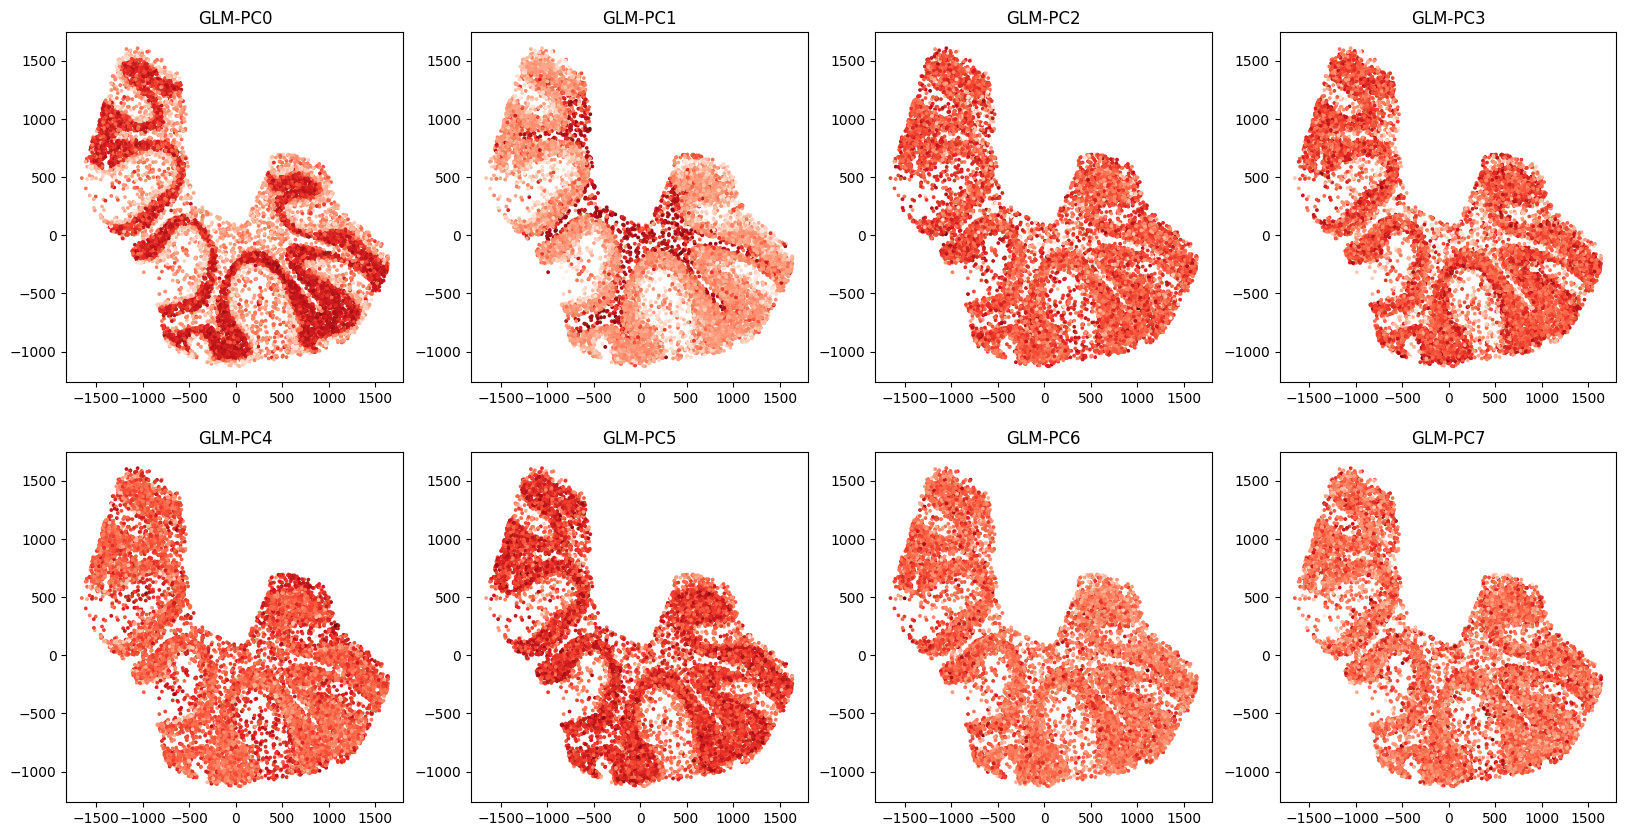

In [31]:
# visualize top GLM-PCs
R=2
C=4
fig,axs=plt.subplots(R,C,figsize=(20,10))
for r in range(R):
    for c in range(C):
        i=r*C+c
        axs[r,c].scatter(coords_mat[:,0], coords_mat[:,1], c=A[:,i],cmap='Reds',s=3)
        axs[r,c].set_title(f'GLM-PC{i}')

In [32]:
S = coords_mat.copy()

# z-score normalize S and A
S_torch, A_torch = neural_net.load_rescale_input_data(S,A)

In [33]:
######################################
# NEURAL NET PARAMETERS (USER CAN CHANGE)
# architectures are encoded as list, eg [20,20] means two hidden layers of size 20 hidden neurons
isodepth_arch=[20,20] # architecture for isodepth neural network d(x,y) : R^2 -> R 
expression_fn_arch=[20,20] # architecture for 1-D expression function h(w) : R -> R^G

num_epochs = 10000 # number of epochs to train NN (NOTE: it is sometimes beneficial to train longer)
checkpoint = 500 # save model after number of epochs = multiple of checkpoint
out_dir='cerebellum_tutorial_outputs' # folder to save model runs
optimizer = "adam"
num_restarts=30
device='cpu' # change to 'cpu' if you don't have a GPU

######################################

seed_list=range(num_restarts)
for seed in seed_list:
    print(f'training neural network for seed {seed}')
    out_dir_seed=f"{out_dir}/seed{seed}"
    os.makedirs(out_dir_seed, exist_ok=True)
    mod, loss_list = neural_net.train(S_torch, A_torch,
                          S_hidden_list=isodepth_arch, A_hidden_list=expression_fn_arch, 
                          epochs=num_epochs, checkpoint=checkpoint, device=device,
                          save_dir=out_dir_seed, optim=optimizer, seed=seed, save_final=True)

training neural network for seed 0
Training on device: cpu
epoch: 0
epoch: 500
epoch: 1000
epoch: 1500
epoch: 2000
epoch: 2500
epoch: 3000
epoch: 3500
epoch: 4000
epoch: 4500
epoch: 5000
epoch: 5500
epoch: 6000
epoch: 6500
epoch: 7000
epoch: 7500
epoch: 8000
epoch: 8500
epoch: 9000
epoch: 9500
training neural network for seed 1
Training on device: cpu
epoch: 0
epoch: 500
epoch: 1000
epoch: 1500
epoch: 2000
epoch: 2500
epoch: 3000
epoch: 3500
epoch: 4000
epoch: 4500
epoch: 5000
epoch: 5500
epoch: 6000
epoch: 6500
epoch: 7000
epoch: 7500
epoch: 8000
epoch: 8500
epoch: 9000
epoch: 9500
training neural network for seed 2
Training on device: cpu
epoch: 0
epoch: 500
epoch: 1000
epoch: 1500
epoch: 2000
epoch: 2500
epoch: 3000
epoch: 3500
epoch: 4000
epoch: 4500
epoch: 5000
epoch: 5500
epoch: 6000
epoch: 6500
epoch: 7000
epoch: 7500
epoch: 8000
epoch: 8500
epoch: 9000
epoch: 9500
training neural network for seed 3
Training on device: cpu
epoch: 0
epoch: 500
epoch: 1000
epoch: 1500
epoch: 2000



best model: cerebellum_tutorial_outputs/seed21
Kneedle number of domains: 4


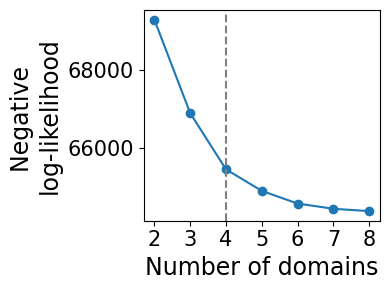

In [34]:
gaston_model, A, S= process_NN_output.process_files('cerebellum_tutorial_outputs', seed_list = seed_list)

model_selection.plot_ll_curve(gaston_model, A, S, max_domain_num=8, start_from=2, num_buckets=100)

In [35]:
# CHANGE FOR YOUR APPLICATION: use number of domains from above!
num_layers=4 

# identify labels
gaston_isodepth, gaston_labels=dp_related.get_isodepth_labels(gaston_model,A,S,num_layers)

# DATASET-SPECIFIC: so domains are ordered oligodendrocyte to molecular, with increasing isodepth
gaston_isodepth=np.max(gaston_isodepth) - gaston_isodepth
gaston_labels=(num_layers-1)-gaston_labels

In [ ]:
scale_factor= 64/100 # since 64 pixels = 100 microns in slide-seq image

# WITH VISUALIZATION
# gaston_isodepth=isodepth_scaling.adjust_isodepth(gaston_isodepth, gaston_labels, coords_mat, 
#                                  q_vals=[0.2, 0.05, 0.15, 0.3], visualize=True, figsize=(12,12),num_rows=2)

# WITHOUT
gaston_isodepth=isodepth_scaling.adjust_isodepth(gaston_isodepth, gaston_labels, coords_mat, 
                                 q_vals=[0.2, 0.05, 0.15, 0.3], scale_factor=scale_factor)

# stash the Default-Coords result before the Error-Coords run below
# reuses (overwrites) these same variable names
gaston_isodepth_default = gaston_isodepth.copy()
gaston_labels_default = gaston_labels.copy()

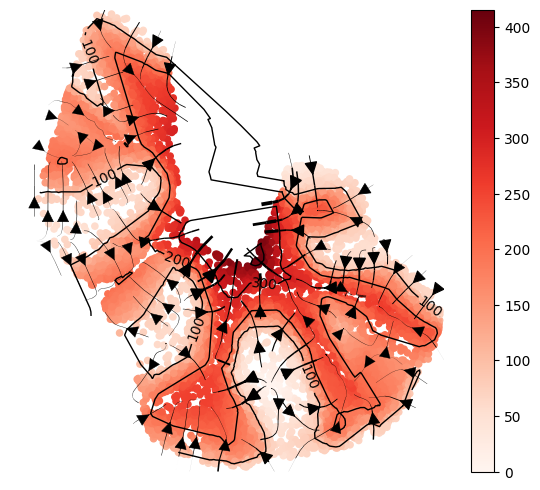

In [37]:
show_streamlines=True
cluster_plotting.plot_isodepth(gaston_isodepth, S, gaston_model, figsize=(7,6), streamlines=show_streamlines, cmap='Reds',
                              neg_gradient=True) # since we did isodepth -> -1*isodepth above, we also need to do gradient -> -1*gradient


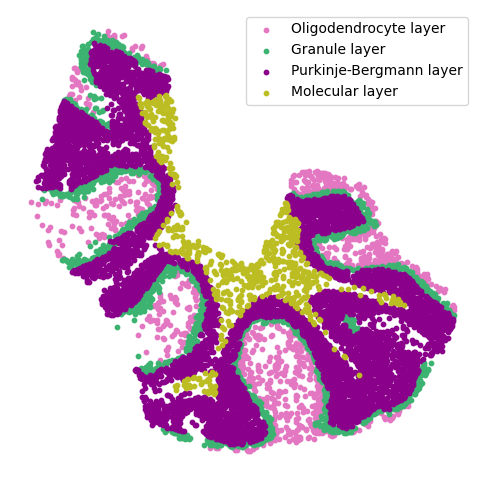

In [48]:
labels=['Oligodendrocyte layer', 'Granule layer', 'Purkinje-Bergmann layer', 'Molecular layer']

# WITHOUT CUSTOM COLORS
# cluster_plotting.plot_clusters(gaston_labels, S, figsize=(6,6), colors=None, 
#                                color_palette=plt.cm.Dark2, s=10,labels=labels,lgd=True)

# TO PLOT WITH CUSTOM COLORS:
domain_colors=['C6', 'mediumseagreen', 'darkmagenta', 'C8']
cluster_plotting.plot_clusters(gaston_labels, S, figsize=(6,6), 
                               colors=domain_colors, s=10,labels=labels,lgd=True)
plt.gcf().savefig('default_Gaston1.png')

In [44]:
cell_type_df=pd.read_csv('cell_type_df.csv', index_col=0)
cell_type_df

,Astrocytes,Bergmann,Candelabrum,Choroid,Endothelial,Ependymal,Fibroblast,Globular,Golgi,Granule,Lugaro,MLI1,MLI2,Macrophages,Microglia,Oligodendrocytes,Polydendrocytes,Purkinje,UBCs
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9980,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
9981,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9982,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9983,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.0,0.0,0.0


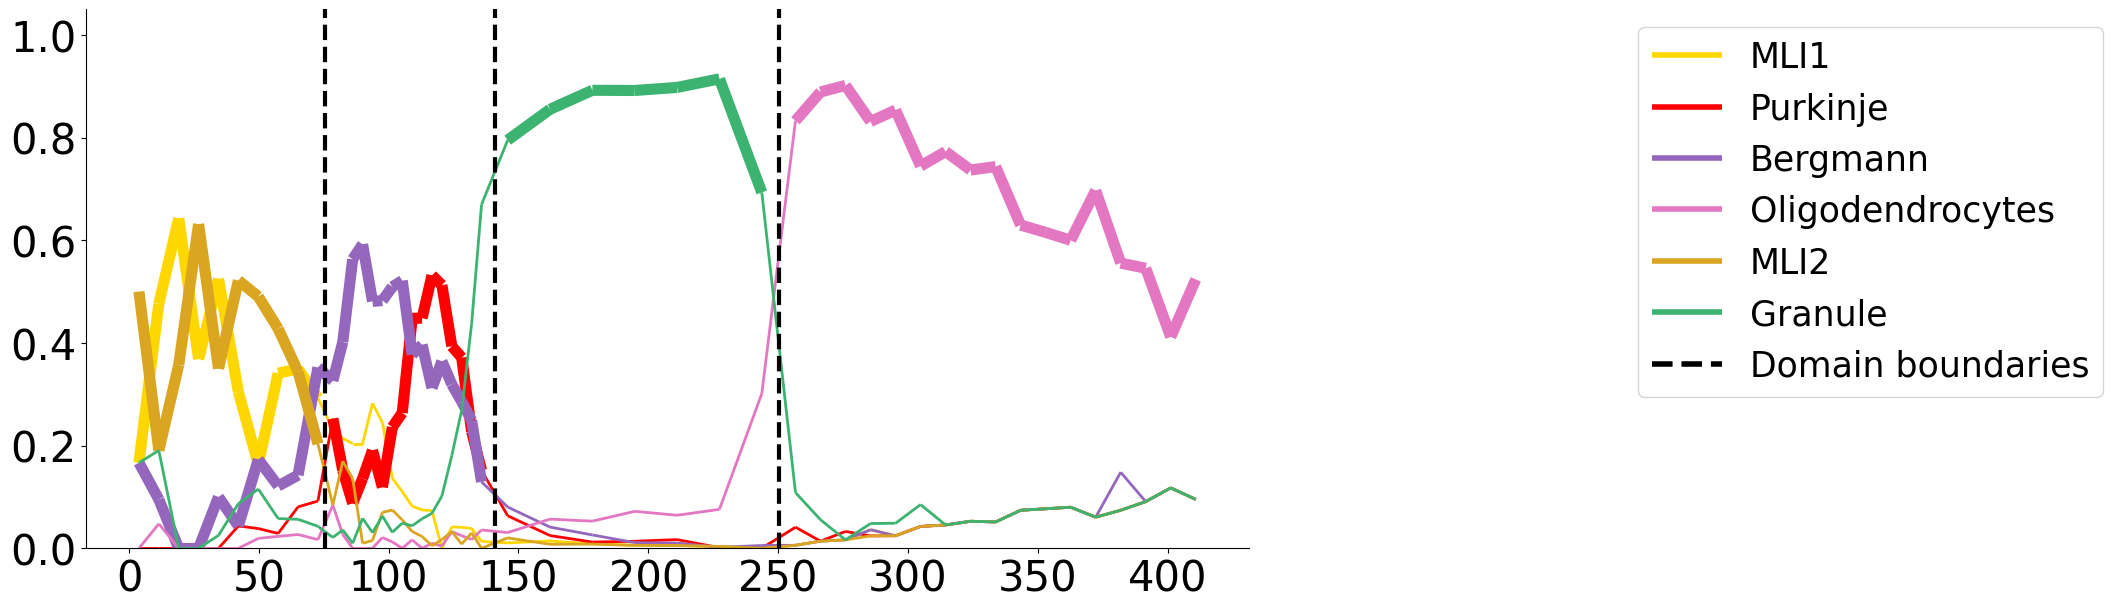

In [47]:
ct_colors={'Oligodendrocytes': 'C6', 'Granule': 'mediumseagreen', 'Purkinje': 'red', 
           'Bergmann': 'C4', 'MLI1': 'gold', 'MLI2': 'goldenrod',  'Astrocytes': 'C0', 
           'Golgi': 'C9', 'Fibroblast': 'C5'}

plot_cell_types.plot_ct_props(cell_type_df, gaston_labels, gaston_isodepth, 
                              num_bins_per_domain=[10,16,7,17], ct_colors=ct_colors, ct_pseudocounts={3:1}, 
                              include_lgd=True, figsize=(15,7), ticksize=30, width1=8, width2=2, 
                              domain_ct_threshold=0.5,)
plt.gcf().savefig('default_Gaston2.png')

## Using Error Coords

Iteration: 0 | deviance=6.0256E+7
Iteration: 1 | deviance=6.0256E+7
Iteration: 2 | deviance=6.0157E+7
Iteration: 3 | deviance=5.7979E+7
Iteration: 4 | deviance=5.7360E+7
Iteration: 5 | deviance=5.7132E+7
Iteration: 6 | deviance=5.7023E+7
Iteration: 7 | deviance=5.6967E+7
Iteration: 8 | deviance=5.6934E+7
Iteration: 9 | deviance=5.6912E+7
Iteration: 10 | deviance=5.6897E+7
Iteration: 11 | deviance=5.6885E+7
Iteration: 12 | deviance=5.6876E+7
Iteration: 13 | deviance=5.6868E+7
Iteration: 14 | deviance=5.6862E+7


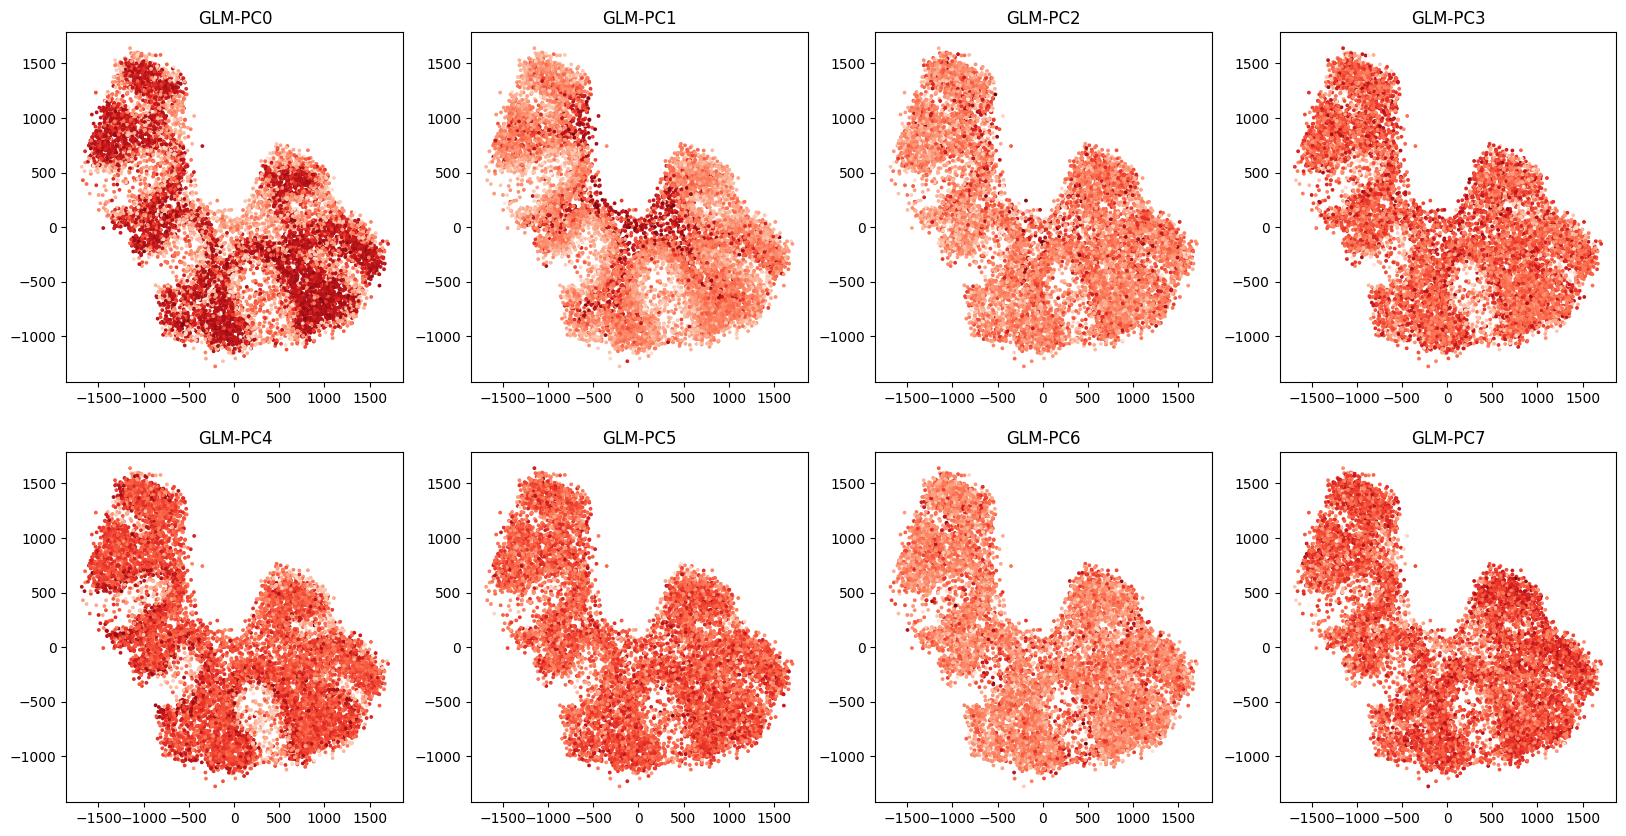

training neural network for seed 0
Training on device: cpu
epoch: 0
epoch: 500
epoch: 1000
epoch: 1500
epoch: 2000
epoch: 2500
epoch: 3000
epoch: 3500
epoch: 4000
epoch: 4500
epoch: 5000
epoch: 5500
epoch: 6000
epoch: 6500
epoch: 7000
epoch: 7500
epoch: 8000
epoch: 8500
epoch: 9000
epoch: 9500
training neural network for seed 1
Training on device: cpu
epoch: 0
epoch: 500
epoch: 1000
epoch: 1500
epoch: 2000
epoch: 2500
epoch: 3000
epoch: 3500
epoch: 4000
epoch: 4500
epoch: 5000
epoch: 5500
epoch: 6000
epoch: 6500
epoch: 7000
epoch: 7500
epoch: 8000
epoch: 8500
epoch: 9000
epoch: 9500
training neural network for seed 2
Training on device: cpu
epoch: 0
epoch: 500
epoch: 1000
epoch: 1500
epoch: 2000
epoch: 2500
epoch: 3000
epoch: 3500
epoch: 4000
epoch: 4500
epoch: 5000
epoch: 5500
epoch: 6000
epoch: 6500
epoch: 7000
epoch: 7500
epoch: 8000
epoch: 8500
epoch: 9000
epoch: 9500
training neural network for seed 3
Training on device: cpu
epoch: 0
epoch: 500
epoch: 1000
epoch: 1500
epoch: 2000


In [49]:
# GLM-PCA parameters
num_dims=8 # 2 * number of clusters
penalty=10 # may need to increase if this is too small

# CHANGE THESE PARAMETERS TO REDUCE RUNTIME
num_iters=30
eps=1e-4
num_genes=30000


counts_mat = ad.X.copy()
coords_mat = ad.obsm['spatial_err']

counts_mat_glmpca=counts_mat[:,np.argsort(np.sum(counts_mat, axis=0))[-num_genes:]]
glmpca_res=glmpca.glmpca(counts_mat_glmpca.T, num_dims, fam="poi", penalty=penalty, verbose=True,
                        ctl = {"maxIter":num_iters, "eps":eps, "optimizeTheta":True})
A = glmpca_res['factors'] # should be of size N x num_dims, where each column is a PC

# visualize top GLM-PCs
R=2
C=4
fig,axs=plt.subplots(R,C,figsize=(20,10))
for r in range(R):
    for c in range(C):
        i=r*C+c
        axs[r,c].scatter(coords_mat[:,0], coords_mat[:,1], c=A[:,i],cmap='Reds',s=3)
        axs[r,c].set_title(f'GLM-PC{i}')
plt.show()
plt.close()


S = coords_mat.copy()

# z-score normalize S and A
S_torch, A_torch = neural_net.load_rescale_input_data(S,A)

######################################
# NEURAL NET PARAMETERS (USER CAN CHANGE)
# architectures are encoded as list, eg [20,20] means two hidden layers of size 20 hidden neurons
isodepth_arch=[20,20] # architecture for isodepth neural network d(x,y) : R^2 -> R 
expression_fn_arch=[20,20] # architecture for 1-D expression function h(w) : R -> R^G

num_epochs = 10000 # number of epochs to train NN (NOTE: it is sometimes beneficial to train longer)
checkpoint = 500 # save model after number of epochs = multiple of checkpoint
out_dir='cerebellum_tutorial_outputs' # folder to save model runs
optimizer = "adam"
num_restarts=30
device='cpu' # change to 'cpu' if you don't have a GPU

######################################

seed_list=range(num_restarts)
for seed in seed_list:
    print(f'training neural network for seed {seed}')
    out_dir_seed=f"{out_dir}/seed{seed}"
    os.makedirs(out_dir_seed, exist_ok=True)
    mod, loss_list = neural_net.train(S_torch, A_torch,
                          S_hidden_list=isodepth_arch, A_hidden_list=expression_fn_arch, 
                          epochs=num_epochs, checkpoint=checkpoint, device=device,
                          save_dir=out_dir_seed, optim=optimizer, seed=seed, save_final=True)


best model: cerebellum_tutorial_outputs/seed19
Kneedle number of domains: 4


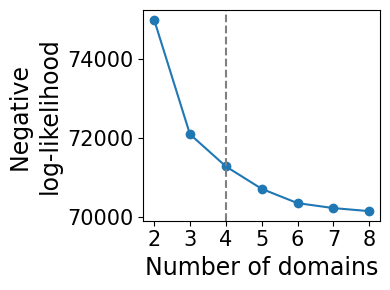

In [50]:
gaston_model, A, S= process_NN_output.process_files('cerebellum_tutorial_outputs', seed_list = seed_list)

model_selection.plot_ll_curve(gaston_model, A, S, max_domain_num=8, start_from=2, num_buckets=100)

In [51]:
# CHANGE FOR YOUR APPLICATION: use number of domains from above!
num_layers=4 

# identify labels
gaston_isodepth, gaston_labels=dp_related.get_isodepth_labels(gaston_model,A,S,num_layers)

# DATASET-SPECIFIC: so domains are ordered oligodendrocyte to molecular, with increasing isodepth
gaston_isodepth=np.max(gaston_isodepth) - gaston_isodepth
gaston_labels=(num_layers-1)-gaston_labels

In [52]:
scale_factor= 64/100 # since 64 pixels = 100 microns in slide-seq image

# WITH VISUALIZATION
# gaston_isodepth=isodepth_scaling.adjust_isodepth(gaston_isodepth, gaston_labels, coords_mat, 
#                                  q_vals=[0.2, 0.05, 0.15, 0.3], visualize=True, figsize=(12,12),num_rows=2)

# WITHOUT
gaston_isodepth=isodepth_scaling.adjust_isodepth(gaston_isodepth, gaston_labels, coords_mat, 
                                 q_vals=[0.2, 0.05, 0.15, 0.3], scale_factor=scale_factor)

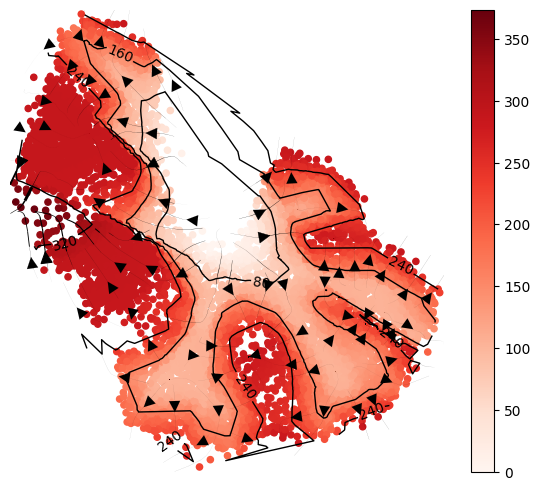

In [53]:
show_streamlines=True
cluster_plotting.plot_isodepth(gaston_isodepth, S, gaston_model, figsize=(7,6), streamlines=show_streamlines, cmap='Reds',
                              neg_gradient=True) # since we did isodepth -> -1*isodepth above, we also need to do gradient -> -1*gradient


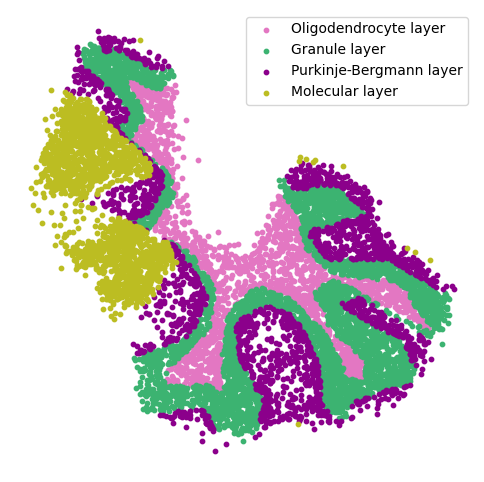

In [55]:
labels=['Oligodendrocyte layer', 'Granule layer', 'Purkinje-Bergmann layer', 'Molecular layer']

# WITHOUT CUSTOM COLORS
# cluster_plotting.plot_clusters(gaston_labels, S, figsize=(6,6), colors=None, 
#                                color_palette=plt.cm.Dark2, s=10,labels=labels,lgd=True)

# TO PLOT WITH CUSTOM COLORS:
domain_colors=['C6', 'mediumseagreen', 'darkmagenta', 'C8']
cluster_plotting.plot_clusters(gaston_labels, S, figsize=(6,6), 
                               colors=domain_colors, s=10,labels=labels,lgd=True)
plt.gcf().savefig('new_Gaston1.png')

In [56]:
cell_type_df=pd.read_csv('cell_type_df.csv', index_col=0)
cell_type_df

,Astrocytes,Bergmann,Candelabrum,Choroid,Endothelial,Ependymal,Fibroblast,Globular,Golgi,Granule,Lugaro,MLI1,MLI2,Macrophages,Microglia,Oligodendrocytes,Polydendrocytes,Purkinje,UBCs
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9980,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
9981,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9982,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9983,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.0,0.0,0.0


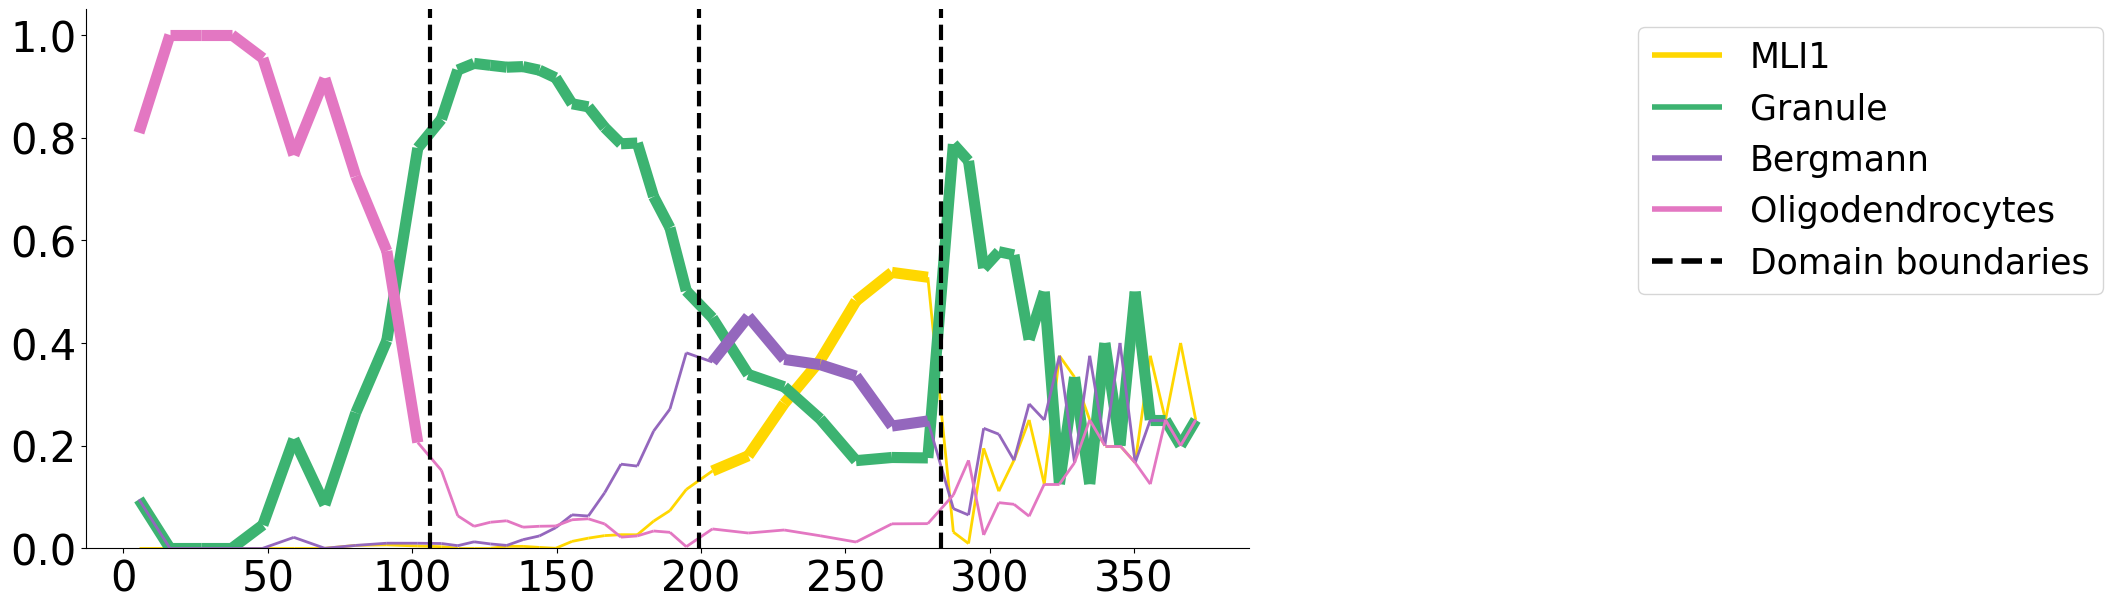

In [57]:
ct_colors={'Oligodendrocytes': 'C6', 'Granule': 'mediumseagreen', 'Purkinje': 'red', 
           'Bergmann': 'C4', 'MLI1': 'gold', 'MLI2': 'goldenrod',  'Astrocytes': 'C0', 
           'Golgi': 'C9', 'Fibroblast': 'C5'}

plot_cell_types.plot_ct_props(cell_type_df, gaston_labels, gaston_isodepth, 
                              num_bins_per_domain=[10,16,7,17], ct_colors=ct_colors, ct_pseudocounts={3:1}, 
                              include_lgd=True, figsize=(15,7), ticksize=30, width1=8, width2=2, 
                              domain_ct_threshold=0.5)
plt.gcf().savefig('new_Gaston2.png')

## Quantitative comparison: Default vs Error

In [ ]:
# Quantitative GASTON concordance: Default Coords vs Error Coords,
# matching Concordex's agreement metric below. ARI is label-permutation-
# invariant (domain 0 in one run need not correspond to domain 0 in the
# other); Spearman rho compares the continuous isodepth values directly.
from sklearn.metrics import adjusted_rand_score
from scipy.stats import spearmanr

gaston_ari = adjusted_rand_score(gaston_labels_default, gaston_labels)
gaston_rho, gaston_p = spearmanr(gaston_isodepth_default, gaston_isodepth)
print(f"GASTON domain-label agreement (ARI, Default vs Error coords): {gaston_ari:.3f}")
print(f"GASTON isodepth correlation (Spearman rho, Default vs Error coords): "
      f"{gaston_rho:.3f} (p={gaston_p:.2e})")

## Using Mixture-Error Coords

**Compute cost note:** this repeats the full GLM-PCA + multi-seed,
10,000-epoch neural network training pipeline used above for "Using
Error Coords" -- the same cost as that section, run a third time. Uses
a separate output directory (`cerebellum_tutorial_outputs_mix`) so it
does not overwrite the Default/Error runs' saved model checkpoints
(those two currently share one directory and the same seed numbers --
a separate, pre-existing fragility worth fixing at some point, out of
scope here).

In [ ]:
# GLM-PCA parameters (identical to the Default/Error sections above)
num_dims=8
penalty=10
num_iters=30
eps=1e-4
num_genes=30000

counts_mat = ad.X.copy()
coords_mat = ad.obsm['spatial_mix']

counts_mat_glmpca=counts_mat[:,np.argsort(np.sum(counts_mat, axis=0))[-num_genes:]]
glmpca_res=glmpca.glmpca(counts_mat_glmpca.T, num_dims, fam="poi", penalty=penalty, verbose=True,
                        ctl = {"maxIter":num_iters, "eps":eps})
A=glmpca_res['factors']

In [ ]:
S = coords_mat.copy()
S_torch, A_torch = neural_net.load_rescale_input_data(S,A)

In [ ]:
isodepth_arch=[20,20]
expression_fn_arch=[20,20]
num_epochs = 10000
checkpoint = 500
out_dir='cerebellum_tutorial_outputs_mix'
optimizer = "adam"
num_restarts=30
device='cpu'
seed_list=range(num_restarts)

for seed in seed_list:
    print(f'training neural network for seed {seed}')
    out_dir_seed=f"{out_dir}/seed{seed}"
    os.makedirs(out_dir_seed, exist_ok=True)
    mod, loss_list = neural_net.train(S_torch, A_torch,
                          S_hidden_list=isodepth_arch, A_hidden_list=expression_fn_arch,
                          epochs=num_epochs, checkpoint=checkpoint, device=device,
                          save_dir=out_dir_seed, optim=optimizer, seed=seed, save_final=True)

In [ ]:
gaston_model, A, S = process_NN_output.process_files('cerebellum_tutorial_outputs_mix', seed_list=seed_list)
model_selection.plot_ll_curve(gaston_model, A, S, max_domain_num=8, start_from=2, num_buckets=100)

In [ ]:
num_layers=4
gaston_isodepth, gaston_labels = dp_related.get_isodepth_labels(gaston_model, A, S, num_layers)
gaston_isodepth = np.max(gaston_isodepth) - gaston_isodepth
gaston_labels = (num_layers-1) - gaston_labels

scale_factor = 64/100
gaston_isodepth = isodepth_scaling.adjust_isodepth(gaston_isodepth, gaston_labels, coords_mat,
                                 q_vals=[0.2, 0.05, 0.15, 0.3], scale_factor=scale_factor)

In [ ]:
cluster_plotting.plot_isodepth(gaston_isodepth, S, gaston_model, figsize=(7,6), streamlines=True,
                              cmap='Reds', neg_gradient=True)

## Quantitative comparison: Default vs Mixture

In [ ]:
from sklearn.metrics import adjusted_rand_score
from scipy.stats import spearmanr

gaston_ari_mix = adjusted_rand_score(gaston_labels_default, gaston_labels)
gaston_rho_mix, gaston_p_mix = spearmanr(gaston_isodepth_default, gaston_isodepth)
print(f"GASTON domain-label agreement (ARI, Default vs Mixture coords): {gaston_ari_mix:.3f}")
print(f"GASTON isodepth correlation (Spearman rho, Default vs Mixture coords): "
      f"{gaston_rho_mix:.3f} (p={gaston_p_mix:.2e})")

GASTON domain-label agreement (ARI, Default vs Mixture coords): 0.278
GASTON isodepth correlation (Spearman rho, Default vs Mixture coords): 0.290 (p=2.90e-193)


# Set up Concordex

In [24]:
from concordex.tools import calculate_concordex
from scipy.cluster.vq import kmeans2

In [25]:
ad.obsm['spatial'].max(axis=0), ad.obsm['spatial'].min(axis=0), 

(array([1638.74197929, 1609.20211062]),
 array([-1654.59230643, -1127.13262622]))

In [26]:
ad

AnnData object with n_obs × n_vars = 9985 × 10121
    obs: 'row', 'col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_counts', 'n_genes', 'x', 'y', 'error', 'x_err', 'y_err'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca', 'spatial', 'spatial_err', 'spatial_mix'
    varm: 'PCs'

Computing nearest neighbors...

Computing neighborhood consolidation matrix...



/Users/ConradOakes/miniconda3/envs/op_error_test/lib/python3.11/site-packages/concordex/neighbors/_neighborhood.py:61: UserWarning: Expected discrete labels to compute similarity matrix
  warnings.warn("Expected discrete labels to compute similarity matrix")
/Users/ConradOakes/miniconda3/envs/op_error_test/lib/python3.11/site-packages/anndata/_core/aligned_mapping.py:285: ImplicitModificationWarning: Obsm 'X_nbc' should not be a np.matrix, use np.ndarray instead.
  return super()._validate_value(val, key)
/var/folders/kj/wm2vrp3x04qgzq18l2rkrcxh0000gn/T/ipykernel_23293/1106136249.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad, color="Concordex (Truth)", spot_size=4, size=4,


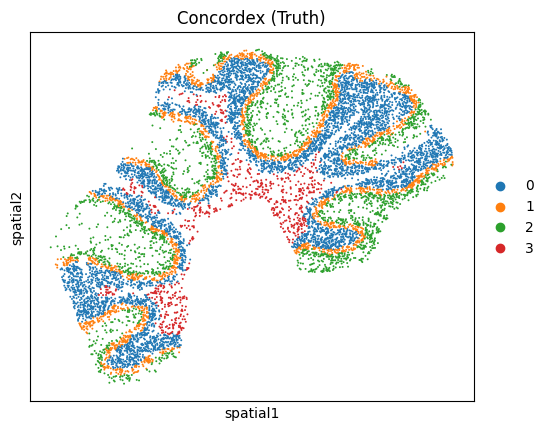

In [27]:
calculate_concordex(ad, 'X_pca', use_rep="spatial", compute_similarity=True)
_, shr = kmeans2(ad.obsm['X_nbc'], 4)
ad.obs['Concordex (Truth)'] = pd.Categorical(shr)
sc.pl.spatial(ad, color="Concordex (Truth)", spot_size=4, size=4,
             save = 'Supp_4a.png')

## Add Location error

In [28]:
# generate error -- local, explicitly-seeded RNG (see cell above the
# Gaston section for why); and write into NEW x_err/y_err/spatial_err
# columns rather than overwriting ad.obs['x']/['y']/ad.obsm['spatial']
# in place. The original code overwrote the clean coordinates here,
# which only worked because 'Concordex (Truth)' (two cells above) had
# already been computed and cached -- re-running cells out of order, or
# refactoring this into a function, would have silently corrupted the
# 'Truth' reference since the clean coordinates no longer existed
# anywhere afterward.
err_rng2 = np.random.RandomState(43)   # different seed from the Gaston draw -- independent realization
ad.obs['error'] = stats.gamma.rvs(shape_g, loc=loc_g, scale=scale_g, size=len(ad.obs), random_state=err_rng2)
theta = err_rng2.uniform(0, 2*np.pi, size=len(ad.obs))
ad.obs['x_err'] = ad.obs['x'] + ad.obs['error'] * np.cos(theta)
ad.obs['y_err'] = ad.obs['y'] + ad.obs['error'] * np.sin(theta)
ad.obsm['spatial_err'] = ad.obs[['x_err', 'y_err']].values

# sanity check: clean coordinates must be untouched by this point,
# regardless of cell execution order
assert np.allclose(ad.obsm['spatial'], ad.obs[['x', 'y']].values), \
    "clean coordinates were modified -- 'Concordex (Truth)' reference is no longer valid"
ad

AnnData object with n_obs × n_vars = 9985 × 10121
    obs: 'row', 'col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_counts', 'n_genes', 'x', 'y', 'error', 'x_err', 'y_err', 'Concordex (Truth)'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca', 'adj_params', 'nbc_params', 'Concordex (Truth)_colors'
    obsm: 'X_pca', 'spatial', 'spatial_err', 'spatial_mix', 'adjacency', 'X_nbc'
    varm: 'PCs'

Computing nearest neighbors...

Computing neighborhood consolidation matrix...



/Users/ConradOakes/miniconda3/envs/op_error_test/lib/python3.11/site-packages/concordex/neighbors/_neighborhood.py:193: UserWarning: A neighborhood graph already exists at ``adata.obsm[adjacency]``.               Set ``recompute_neighbors = TRUE`` to overwrite the existing graph.
  warnings.warn(
/Users/ConradOakes/miniconda3/envs/op_error_test/lib/python3.11/site-packages/concordex/neighbors/_neighborhood.py:61: UserWarning: Expected discrete labels to compute similarity matrix
  warnings.warn("Expected discrete labels to compute similarity matrix")
/Users/ConradOakes/miniconda3/envs/op_error_test/lib/python3.11/site-packages/anndata/_core/aligned_mapping.py:285: ImplicitModificationWarning: Obsm 'X_nbc' should not be a np.matrix, use np.ndarray instead.
  return super()._validate_value(val, key)
/var/folders/kj/wm2vrp3x04qgzq18l2rkrcxh0000gn/T/ipykernel_23293/2168609774.py:5: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad, color="Concordex (with Error)", 

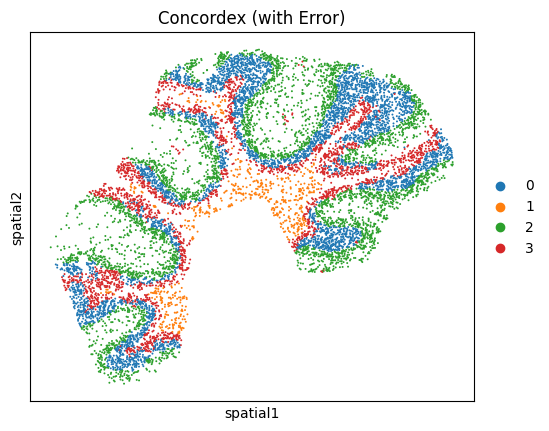

In [29]:
calculate_concordex(ad, 'X_pca', use_rep="spatial_err", compute_similarity=True)
_, shr = kmeans2(ad.obsm['X_nbc'], 4)
ad.obs['Concordex (with Error)'] = pd.Categorical(shr)
#ad.obs['Concordex (with Error)'] = ad.obs['Concordex (with Error)'].replace({0: 2, 2: 0})
sc.pl.spatial(ad, color="Concordex (with Error)", spot_size=4, size=4,
             save = 'Supp_4b.png')

## Mixture (identity-swap) and direct graph-corruption error

In [30]:
# mixture-displacement version -- independent draw from the Gaston one above
mix_rng_concordex = np.random.RandomState(49)
spatial_mix_cx, mix_swapped_cx = inject_mixture_error(ad.obsm['spatial'], p_swap=0.20, rng=mix_rng_concordex)
ad.obsm['spatial_mix'] = spatial_mix_cx
assert np.allclose(ad.obsm['spatial'], ad.obs[['x', 'y']].values), \
    "clean coordinates were modified while building the mixture model"

calculate_concordex(ad, 'X_pca', use_rep="spatial_mix", compute_similarity=True, key_added="mix")
_, shr_mix = kmeans2(ad.obsm['mix_nbc'], 4)
ad.obs['Concordex (with Mixture Error)'] = pd.Categorical(shr_mix)

Computing nearest neighbors...

Computing neighborhood consolidation matrix...



/Users/ConradOakes/miniconda3/envs/op_error_test/lib/python3.11/site-packages/concordex/neighbors/_neighborhood.py:61: UserWarning: Expected discrete labels to compute similarity matrix
  warnings.warn("Expected discrete labels to compute similarity matrix")
/Users/ConradOakes/miniconda3/envs/op_error_test/lib/python3.11/site-packages/anndata/_core/aligned_mapping.py:285: ImplicitModificationWarning: Obsm 'mix_nbc' should not be a np.matrix, use np.ndarray instead.
  return super()._validate_value(val, key)


In [31]:
# direct graph-level corruption -- bypass positional perturbation
# entirely; calculate_concordex reuses any existing graph at
# adata.obsm['graphswap_adjacency'] (verified against the installed
# concordex source: compute_neighbors() skips its own graph construction
# when recompute_neighbors=False, the default, and a graph already exists
# at that key)
graphswap_rng = np.random.RandomState(50)
corrupted_adj = corrupt_knn_graph(ad.obsm['spatial'], n_neighbors=30, p_swap=0.20, rng=graphswap_rng)
ad.obsm['graphswap_adjacency'] = corrupted_adj
ad.uns['graphswap_adj_params'] = {
    'adj_key': 'graphswap_adjacency',
    'params': {'n_neighbors': 30, 'metric': 'euclidean', 'use_rep': 'spatial'},
}

calculate_concordex(ad, 'X_pca', use_rep="spatial", compute_similarity=True,
                    key_added="graphswap", recompute_neighbors=False)
_, shr_gs = kmeans2(ad.obsm['graphswap_nbc'], 4)
ad.obs['Concordex (with Graph-Swap Error)'] = pd.Categorical(shr_gs)

Computing nearest neighbors...

Computing neighborhood consolidation matrix...



/Users/ConradOakes/miniconda3/envs/op_error_test/lib/python3.11/site-packages/concordex/neighbors/_neighborhood.py:193: UserWarning: A neighborhood graph already exists at ``adata.obsm[graphswap_adjacency]``.               Set ``recompute_neighbors = TRUE`` to overwrite the existing graph.
  warnings.warn(
/Users/ConradOakes/miniconda3/envs/op_error_test/lib/python3.11/site-packages/concordex/neighbors/_neighborhood.py:61: UserWarning: Expected discrete labels to compute similarity matrix
  warnings.warn("Expected discrete labels to compute similarity matrix")
/Users/ConradOakes/miniconda3/envs/op_error_test/lib/python3.11/site-packages/anndata/_core/aligned_mapping.py:285: ImplicitModificationWarning: Obsm 'graphswap_nbc' should not be a np.matrix, use np.ndarray instead.
  return super()._validate_value(val, key)


/var/folders/kj/wm2vrp3x04qgzq18l2rkrcxh0000gn/T/ipykernel_23293/1513439212.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad, color="Concordex (Truth)", spot_size=4, size=4)


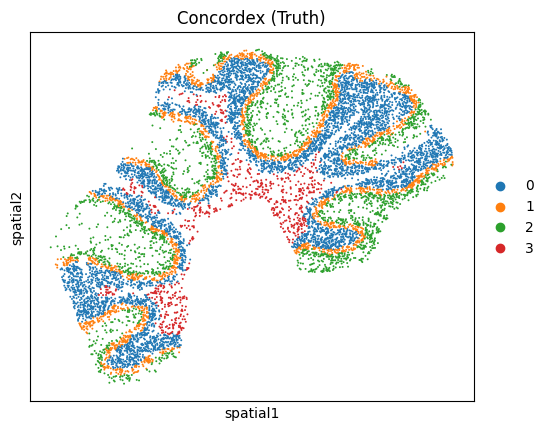

In [32]:
sc.pl.spatial(ad, color="Concordex (Truth)", spot_size=4, size=4)

In [33]:
from wompywompy import plot_alluvial


In [34]:
cluster_df = ad.obs[['Concordex (Truth)', 'Concordex (with Error)']].copy()
cluster_df['value'] = 1
cluster_df = cluster_df.groupby(['Concordex (Truth)', 'Concordex (with Error)']).sum().reset_index()
cluster_df = cluster_df[cluster_df['value'] > 0]
cluster_df['match'] = cluster_df['Concordex (Truth)'] == cluster_df['Concordex (with Error)']

/var/folders/kj/wm2vrp3x04qgzq18l2rkrcxh0000gn/T/ipykernel_23293/3125489720.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_df = cluster_df.groupby(['Concordex (Truth)', 'Concordex (with Error)']).sum().reset_index()


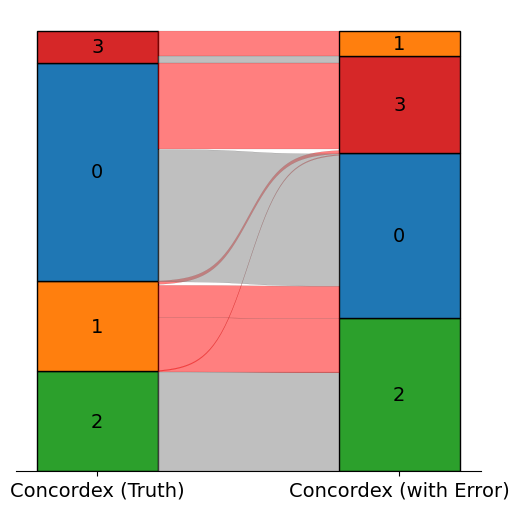

In [35]:
color_dict = {
    '0' : '#1f77b4',
    '1' : '#ff7f0e',
    '2': '#2ca02c',
    '3': '#d62728',
    True: 'grey',
    False: 'red'
    
}

fig, order_dict = plot_alluvial(cluster_df,column_weights = 'value', #pandas data frame  
                  # general function arguments
                                return_order_dict = True, color_dict = color_dict,
                  graphing_columns = ['Concordex (Truth)', 'Concordex (with Error)'], 
              alluvium_column = 'match', color_alluvium = True, match_colors = False, verbose = False,
             sorting_algorithm = 'neighbornet', autofit_text = True, savefig = 'Supp_4c.png')

In [36]:
np.sum(cluster_df['value'] * cluster_df['match'])/cluster_df.value.sum()

0.5396094141211818

In [37]:
cluster_df.value.sum() - np.sum(cluster_df['value'] * cluster_df['match'])

4597

## Extended comparison: all error models

In [38]:
from sklearn.metrics import adjusted_rand_score as _ari

for col in ['Concordex (with Error)', 'Concordex (with Mixture Error)',
           'Concordex (with Graph-Swap Error)']:
    cdf = ad.obs[['Concordex (Truth)', col]].copy()
    naive_match = (cdf['Concordex (Truth)'].astype(str) == cdf[col].astype(str)).mean()
    ari = _ari(cdf['Concordex (Truth)'], cdf[col])
    print(f"{col:38s} ARI={ari:.3f}  (naive raw-label match={naive_match:.3f}, "
          f"not permutation-corrected -- see note below)")
print()
print("ARI is the principled comparison (label-permutation invariant, matching")
print("the GASTON metric above and the alluvial-diagram majority-correspondence")
print("match fraction for 'with Error' printed further up). The naive raw-label")
print("match fraction is included only for reference and is NOT meaningful on its")
print("own -- k-means cluster IDs are arbitrary across independent runs.")

Concordex (with Error)                 ARI=0.431  (naive raw-label match=0.540, not permutation-corrected -- see note below)
Concordex (with Mixture Error)         ARI=0.277  (naive raw-label match=0.073, not permutation-corrected -- see note below)
Concordex (with Graph-Swap Error)      ARI=0.445  (naive raw-label match=0.217, not permutation-corrected -- see note below)

ARI is the principled comparison (label-permutation invariant, matching
the GASTON metric above and the alluvial-diagram majority-correspondence
match fraction for 'with Error' printed further up). The naive raw-label
match fraction is included only for reference and is NOT meaningful on its
own -- k-means cluster IDs are arbitrary across independent runs.


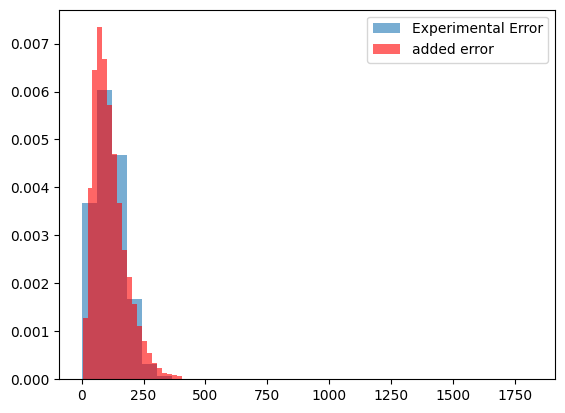

In [ ]:
plt.hist(data, bins=30, density=True, alpha=0.6, label = 'Experimental Error')
plt.hist(ad.obs['error'], bins=30, density=True, alpha=0.6, color='red', label = 'added error')
plt.legend()